In [1]:
import sys
sys.path.append('../')
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.graph_build import calcualte_voronoi_from_coords, build_graph_from_cell_coords, build_graph_from_voronoi_polygons, build_voronoi_polygon_to_cell_mapping, plot_voronoi_polygons, plot_graph, assign_attributes
from hypgs.models.hsn_pyg import HyperScatteringModule
from hypgs.utils.data import get_hyperedge_index
import scanpy as sc
import numpy as np
import pandas as pd
import torch
from torch_geometric.utils.convert import from_networkx
from hypgs.utils.data import HGDataset
from dhg import Hypergraph
import scprep
import matplotlib.pyplot as plt
import re
import phate
from phate.cluster import kmeans
from scipy.spatial import ConvexHull
from torch_geometric.data.hypergraph_data import HyperGraphData
from tqdm import tqdm
from torch_geometric.nn import MessagePassing

class CountCellTypesConv(MessagePassing):
    """
    Count celltypes of neighbors by message passing
    """
    def __init__(self):
        # Initialize with sum aggregation
        super(CountCellTypesConv, self).__init__(aggr='add')

    def forward(self, x, edge_index):
        return self.propagate(edge_index, x=x)

    def message(self, x_j):
        return x_j
    
from scipy.spatial.distance import pdist, squareform, cdist
import pathlib
data_path = '../data/hgsae2/'
pathlib.Path(data_path).mkdir(parents=True, exist_ok=True)


/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:47: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/libpyg.so: undefined symbol: _ZN2at4_ops12split_Tensor4callERKNS_6TensorEN3c106SymIntEl
  warnings.warn(f"An issue occurred while importing 'pyg-lib'. "
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:90: UserWarning: An issue occurred while importing 'torch-spline-conv'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.con

In [2]:
import os
filelist = [f for f in os.listdir("/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/sea_ad/data/hypergraphae/") if f.endswith('.h5ad')]

In [3]:
# for file in filelist:
#     print(f"cd /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/hypergraph_scattering/notebooks; /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/bin/python MLSP_2.1_prepare_embeddings.py --section {file}")

In [4]:
# for section in tqdm(['H20.33.001.CX28.MTG.02.007.1.02.02', 'H20.33.044.Cx26.MTG.02.007.1.01.04', 'H21.33.023.Cx26.MTG.02.007.1.03.05', 'H21.33.019.Cx30.MTG.02.007.5.01.01', 'H21.33.022.Cx26.MTG.02.007.2.M.04', 'H21.33.028.CX28.MTG.02.007.1.01.01']):
# for section in tqdm(filelist):
section = filelist[0]
adata = sc.read_h5ad(f"/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/sea_ad/data/hypergraphae/{section}")

coordinates = adata.obsm['spatial']
coordinates = coordinates - coordinates.min(axis=0)
xmax, ymax = coordinates.max(axis=0)
voronoi_polygons = calcualte_voronoi_from_coords(coordinates[:, 0], coordinates[:, 1])
cell_data = pd.DataFrame(np.c_[adata.obs.index, coordinates], columns=['CELL_ID', 'X', 'Y'])
G, node_to_cell_mapping = build_graph_from_cell_coords(cell_data, voronoi_polygons)
G = assign_attributes(G, cell_data, node_to_cell_mapping)

X = adata.X.toarray()
data = from_networkx(G)
data.x = torch.tensor(X)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, 1)
dataset = HGDataset(original_dataset, to_hg_func)

eidf = get_hyperedge_pos_df(dataset[0], coordinates)
enlarged_hulls = compute_enlarged_hulls(eidf, )
hulls = []
df = eidf
for set_index, group in df.groupby('he_idx'):
    points = group[['x', 'y']].values
    hull = ConvexHull(points)
    hulls.append(hull)
approx_radius = [np.sqrt(hull.volume/np.pi) for hull in hulls]
approx_radius = np.array(approx_radius)
n_cells = [hull.points.shape[0] for hull in hulls]
n_cells = np.array(n_cells)
# fig, axes = plt.subplots(1,2, figsize=(12,6))
# axes[0].hist(approx_radius, 100)
# axes[0].set_xlabel('Approximate Radius')
# axes[1].hist(n_cells, 100)
# axes[1].set_xlabel('Number of Cells')

model = HyperScatteringModule(in_channels=X.shape[1], 
            trainable_laziness = False,
            trainable_scales = False, 
            activation = None, # just get one layer of wavelet transform 
            fixed_weights=True, 
            normalize='right', 
            reshape=False,
        )

s_nodes, s_edges = model(dataset[0].x.float(), dataset[0].edge_index, hyperedge_attr = dataset[0].edge_attr)
shapes = s_edges.size()
he_features = s_edges.squeeze().permute(1,0,2).reshape(shapes[2], shapes[1]*shapes[3])
# torch.save(he_features, "../data/merfish_hyperedge_GS_features.pt")

enc_df = pd.get_dummies(adata.obs[['Class', 'Subclass', 'Supertype']])
encoded_data = torch.tensor(enc_df.values, dtype=torch.float)

data = HyperGraphData(edge_index=dataset[0].edge_index, x=encoded_data)
conv = CountCellTypesConv()
node_feature_counts = conv(data.x, data.edge_index)
count_df = pd.DataFrame(node_feature_counts.cpu().numpy(), columns=enc_df.columns).astype(int)
# count_df.to_csv('../data/merfish_hyperedge_celltypes.csv', index=False)

class_dict = {
    'oligo': ['Oligodendrocyte', 'OPC'],
    'astro': ['Astrocyte'],
    'immune': ['Microglia-PVM'],
    'vascular': ['Endothelial', 'VLMC'],
    'neural': ['L2/3 IT','L6 IT','L4 IT','L5 IT',
        'L5 ET','L6 CT','L6b','L6 IT Car3','L5/6 NP',
        'Lamp5 Lhx6','Lamp5','Pax6','Sncg','Vip',
        'Sst Chodl','Sst','Pvalb','Chandelier']
}

count_coarse = pd.DataFrame(index=count_df.index)
for key, value in class_dict.items():
    value = ['Subclass_'+v for v in value]
    count_coarse[key] = count_df[value].sum(axis=1)
rate_coarse = count_coarse/n_cells.reshape(-1,1)
# binarize the types into 2^5=32 types
count_coarse_bin = (count_coarse > 0).astype(int)
count_coarse_bin_combine = count_coarse_bin.copy()
count_coarse_bin_combine['class'] = count_coarse_bin_combine.applymap(str).sum(axis=1)
count_coarse_bin_combine['class'].value_counts()

heclass = count_coarse_bin_combine['class'].values

# phate_op = phate.PHATE(n_components=3)
# he_phate = phate_op.fit_transform(he_features.detach().numpy())

xor_dist = 1 - (heclass.reshape(1,-1) == heclass.reshape (-1,1))
epsilon = 1e-7 # like phate.
log001p_dist = squareform(pdist(np.log(rate_coarse + epsilon)))
# pca_loadings = phate_op.graph.data_nu
train_mask = np.zeros(len(heclass)).astype(bool)
np.random.seed(42)
train_idx = np.random.choice(len(heclass), int(len(heclass) * 0.8), replace=False)
train_mask[train_idx] = True

# data_dict = dict(
#     data=pca_loadings,
#     phate=he_phate,
#     dist=log001p_dist,
#     colors=heclass,
#     xor_dist=xor_dist,
#     is_train=train_mask,
# )
# np.savez(f"{data_path}/{section}.npz", **data_dict)


/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/utils/convert.py:260: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /opt/conda/conda-bld/pytorch_1670525539683/work/torch/csrc/utils/tensor_new.cpp:230.)
  data[key] = torch.tensor(value)
Converting to hypergraph data: 100%|██████████| 1/1 [00:02<00:00,  2.48s/it]


NameError: name 'phate_op' is not defined

In [5]:
count_coarse

,oligo,astro,immune,vascular,neural
0,3,1,0,1,2
1,0,1,3,2,1
2,1,0,3,0,3
3,1,1,0,0,2
4,3,1,1,0,0
...,...,...,...,...,...
3635,0,2,1,0,2
3636,1,1,4,1,1
3637,1,1,2,0,2
3638,1,2,4,0,1


In [6]:
count_df

,Class_Neuronal: GABAergic,Class_Neuronal: Glutamatergic,Class_Non-neuronal and Non-neural,Subclass_Lamp5 Lhx6,Subclass_Lamp5,Subclass_Pax6,Subclass_Sncg,Subclass_Vip,Subclass_Sst Chodl,Subclass_Sst,...,Supertype_VLMC_1,Supertype_SMC-SEAAD,Supertype_Pericyte_1,Supertype_Pericyte_2-SEAAD,Supertype_Monocyte,Supertype_Micro-PVM_1,Supertype_Micro-PVM_2_1-SEAAD,Supertype_Micro-PVM_2,Supertype_Micro-PVM_2_3-SEAAD,Supertype_Micro-PVM_3-SEAAD
0,1,1,5,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,0,0
1,1,0,6,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,2
2,0,3,4,0,0,0,0,0,0,0,...,0,0,0,0,3,0,0,0,0,0
3,1,1,2,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,0,0,5,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3635,0,2,3,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3636,0,1,7,0,0,0,0,0,0,0,...,0,0,1,0,4,0,0,0,0,0
3637,0,2,4,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3638,1,0,7,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,3


In [11]:
freq_df = count_df/ count_df.sum(axis=1).values.reshape(-1,1)

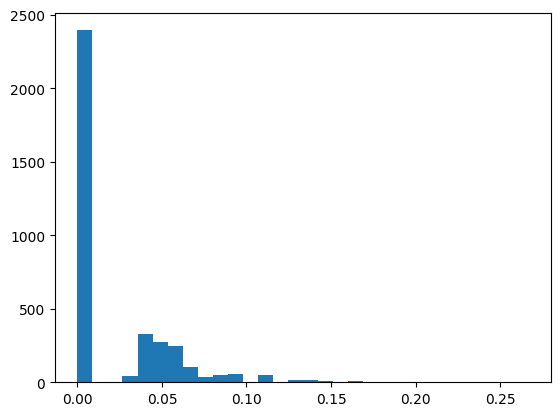

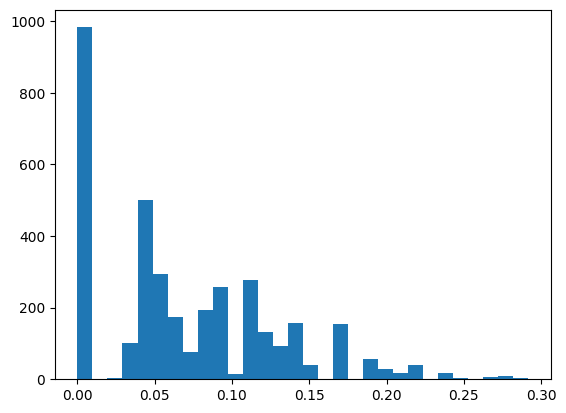

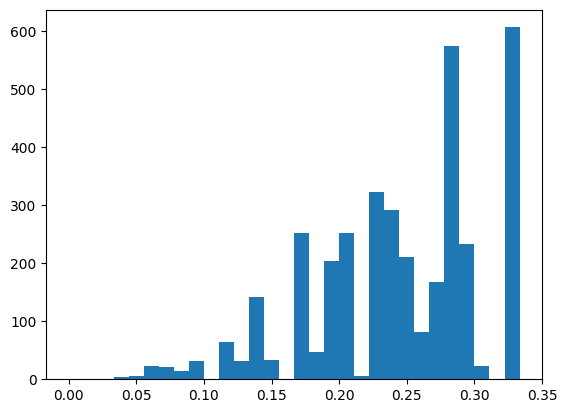

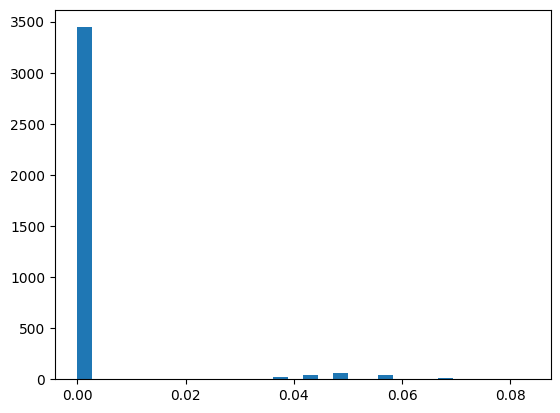

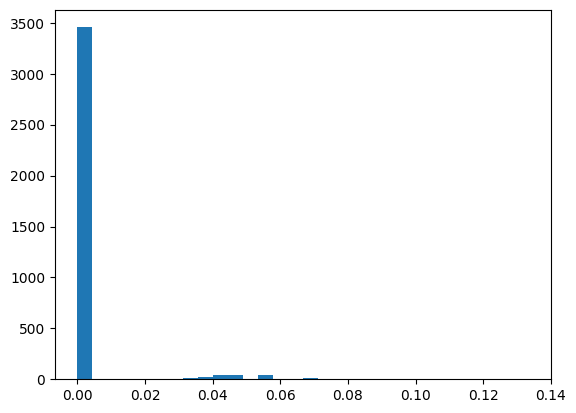

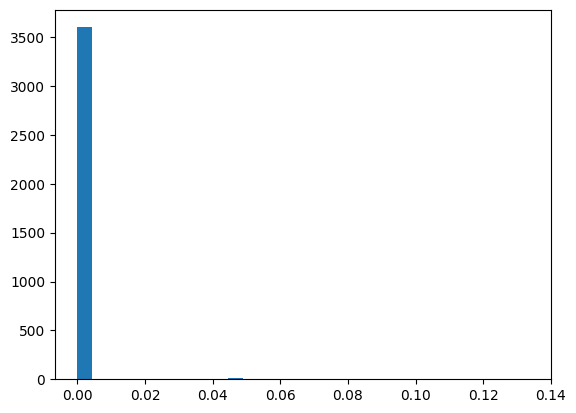

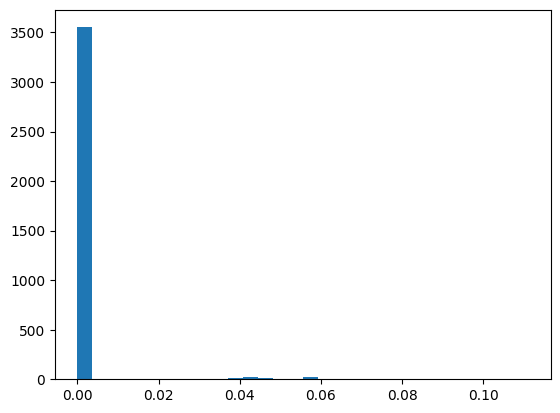

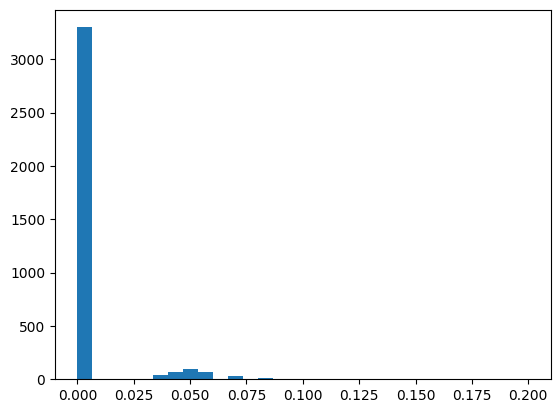

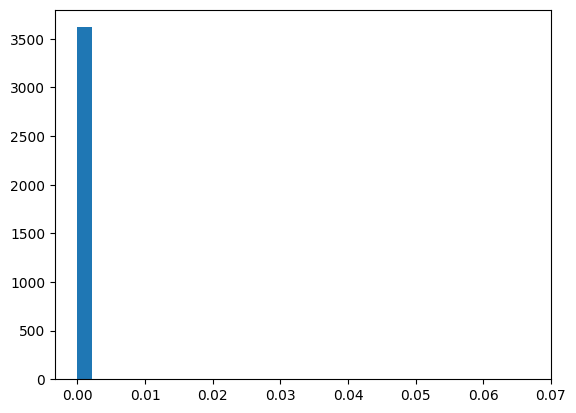

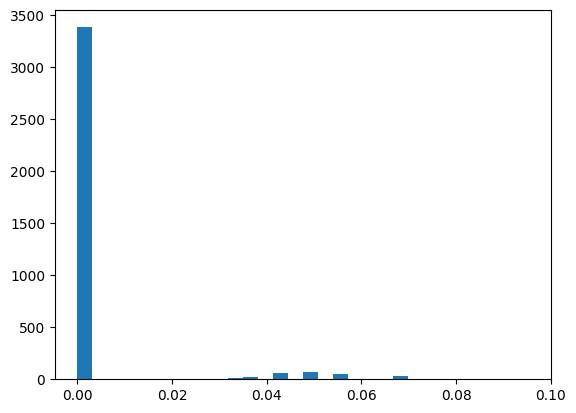

In [13]:
for i in range(10):
    expr = freq_df.iloc[:,i]
    plt.hist(expr, 30)
    plt.show()

In [15]:
phate_op = phate.PHATE(n_components=3, random_state=0)
freq_phate = phate_op.fit_transform(freq_df)

Calculating PHATE...
  Running PHATE on 3640 observations and 138 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.09 seconds.
    Calculating KNN search...
    Calculated KNN search in 1.70 seconds.
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 1.82 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.16 seconds.
    Calculating KMeans...


/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning: Detected zero distance between 39 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    Calculated KMeans in 3.28 seconds.
  Calculated landmark operator in 4.09 seconds.
  Calculating optimal t...
    Automatically selected t = 31
  Calculated optimal t in 2.99 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 1.49 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 36.15 seconds.
Calculated PHATE in 46.56 seconds.


In [41]:
phate_op2 = phate.PHATE(n_components=2, random_state=0)
freq_phate2 = phate_op2.fit_transform(freq_df)

Calculating PHATE...
  Running PHATE on 3640 observations and 138 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.07 seconds.
    Calculating KNN search...
    Calculated KNN search in 2.34 seconds.
    Calculating affinities...
    Calculated affinities in 0.03 seconds.
  Calculated graph and diffusion operator in 2.45 seconds.
  Calculating landmark operator...
    Calculating SVD...


/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning:

Detected zero distance between 39 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.



    Calculated SVD in 0.18 seconds.
    Calculating KMeans...
    Calculated KMeans in 3.04 seconds.
  Calculated landmark operator in 4.20 seconds.
  Calculating optimal t...
    Automatically selected t = 31
  Calculated optimal t in 3.61 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 1.17 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 5.21 seconds.
Calculated PHATE in 16.65 seconds.


In [42]:
from plotly3d.plot import scatter
scatter(freq_phate2, heclass, s=2)

In [22]:
from plotly3d.plot import scatter
scatter(freq_phate, heclass, s=2, filename='hyperedge_celltype_freq_phate.html')

In [23]:
# PCA
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
scaler = StandardScaler()
normalized_data = scaler.fit_transform(freq_df)
pca = PCA(n_components=3)
principal_components = pca.fit_transform(normalized_data)


In [26]:
scatter(principal_components, heclass)

In [25]:
principal_components

array([[ 1.26302247, -0.4819284 ,  0.54532227],
       [-2.43947092,  0.06802865,  0.45018543],
       [ 1.5511157 ,  0.91888439, -2.21986839],
       ...,
       [ 1.04820279, -0.40314665, -1.88634589],
       [-1.64043279, -0.52817875,  1.08992292],
       [ 0.02760738, -2.14189237,  0.6549234 ]])

In [27]:
phate_op_coarse = phate.PHATE(n_components=3, random_state=0)
freq_coarse_phate = phate_op_coarse.fit_transform(rate_coarse)

Calculating PHATE...
  Running PHATE on 3640 observations and 5 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.22 seconds.
    Calculating affinities...
    Calculated affinities in 0.04 seconds.
  Calculated graph and diffusion operator in 0.27 seconds.
  Calculating landmark operator...
    Calculating SVD...


/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning:

Detected zero distance between 10018 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.

/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:454: RuntimeWarning:

overflow encountered in power



    Calculated SVD in 0.23 seconds.
    Calculating KMeans...
    Calculated KMeans in 3.80 seconds.
  Calculated landmark operator in 4.38 seconds.
  Calculating optimal t...
    Automatically selected t = 27
  Calculated optimal t in 0.56 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.18 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 36.38 seconds.
Calculated PHATE in 41.79 seconds.


In [28]:
scatter(freq_coarse_phate, heclass, s=2)

In [29]:
scaler_coarse = StandardScaler()
normalized_data_coarse = scaler_coarse.fit_transform(rate_coarse)
pca_coarse = PCA(n_components=3)
principal_components_coarse = pca_coarse.fit_transform(normalized_data_coarse)


In [30]:
scatter(principal_components_coarse, heclass)

# The weird "grid structure" root in the simplex nature of the poitns. Ideally we should use a the Fisher metric on the simplex.
# Altheratively, if we do not normalize the counts, it would end like this:

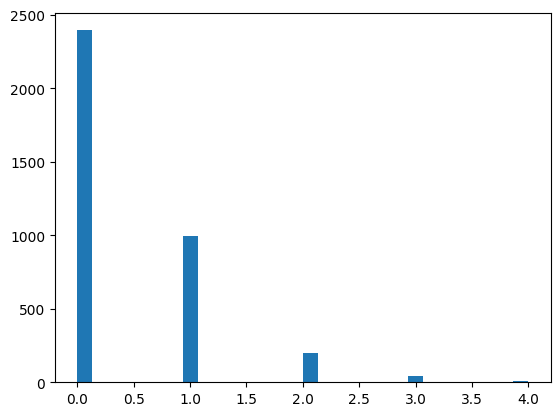

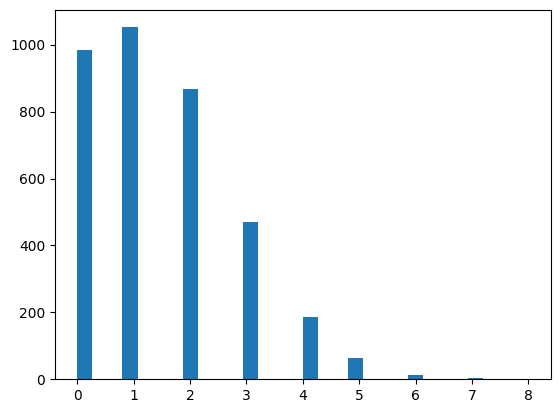

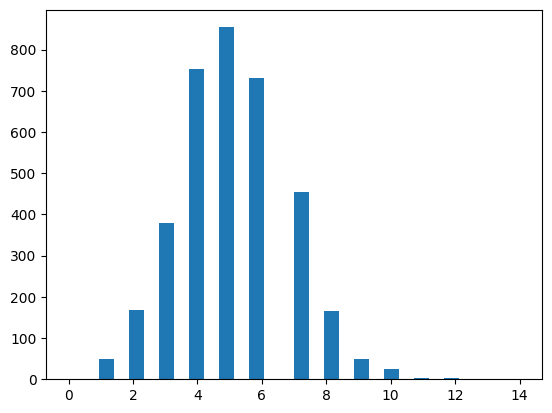

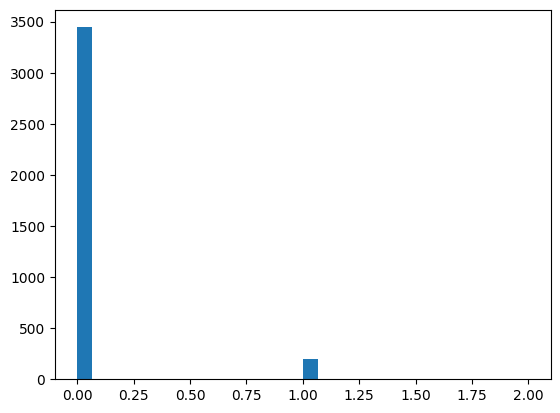

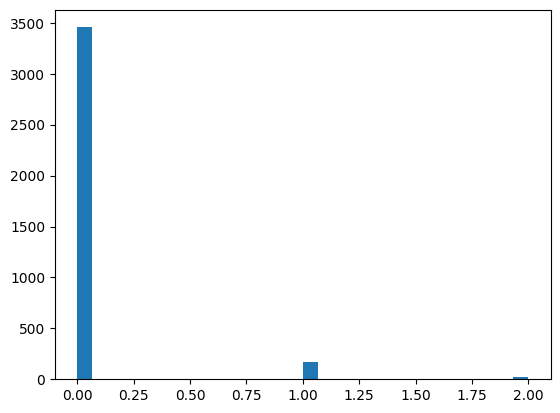

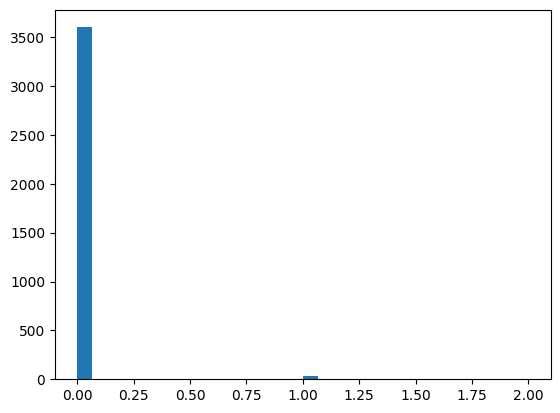

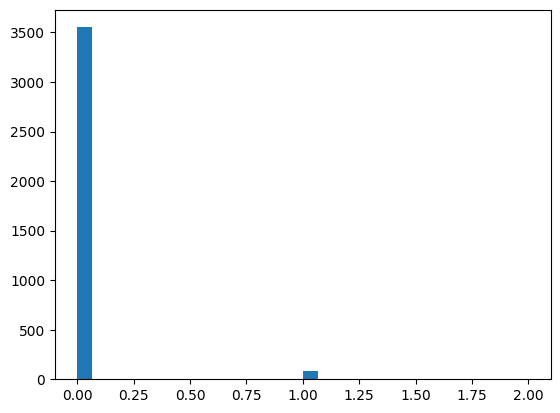

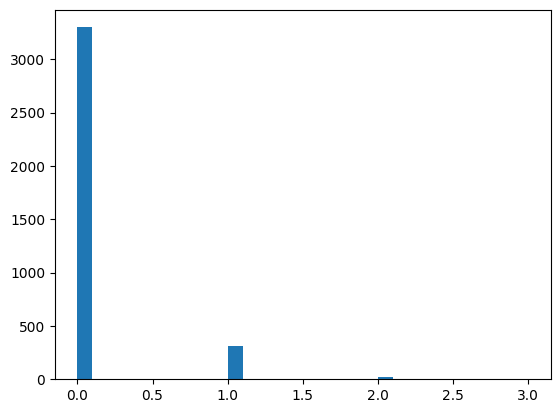

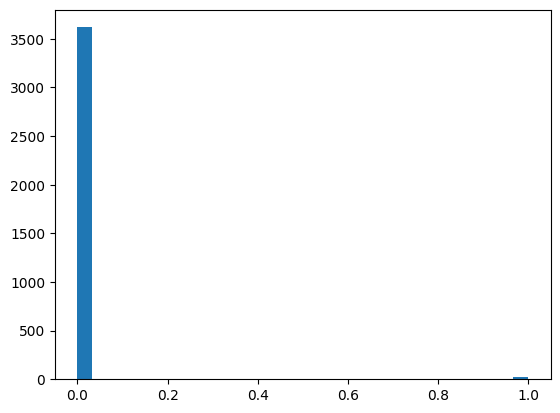

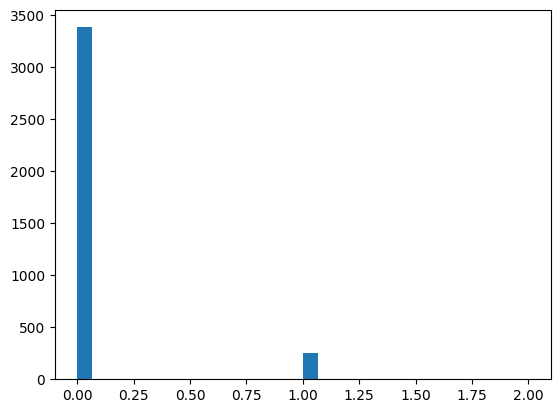

In [31]:
for i in range(10):
    expr = count_df.iloc[:,i]
    plt.hist(expr, 30)
    plt.show()

In [33]:
phate_op = phate.PHATE(n_components=3, random_state=0)
count_phate = phate_op.fit_transform(count_df)

Calculating PHATE...
  Running PHATE on 3640 observations and 138 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.07 seconds.
    Calculating KNN search...
    Calculated KNN search in 2.02 seconds.
    Calculating affinities...
    Calculated affinities in 0.02 seconds.
  Calculated graph and diffusion operator in 2.13 seconds.
  Calculating landmark operator...
    Calculating SVD...


/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning:

Detected zero distance between 39 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.



    Calculated SVD in 0.19 seconds.
    Calculating KMeans...
    Calculated KMeans in 3.36 seconds.
  Calculated landmark operator in 4.19 seconds.
  Calculating optimal t...
    Automatically selected t = 27
  Calculated optimal t in 3.67 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 1.35 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 68.27 seconds.
Calculated PHATE in 79.62 seconds.


In [34]:
from plotly3d.plot import scatter
scatter(count_phate, heclass, s=2, filename='hyperedge_celltype_count_phate.html')

(array([4.400e+01, 0.000e+00, 4.190e+02, 0.000e+00, 9.650e+02, 0.000e+00,
        1.031e+03, 0.000e+00, 7.240e+02, 0.000e+00, 3.040e+02, 0.000e+00,
        1.030e+02, 0.000e+00, 3.200e+01, 0.000e+00, 8.000e+00, 0.000e+00,
        3.000e+00, 0.000e+00, 2.000e+00, 0.000e+00, 4.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00]),
 array([12. , 13.5, 15. , 16.5, 18. , 19.5, 21. , 22.5, 24. , 25.5, 27. ,
        28.5, 30. , 31.5, 33. , 34.5, 36. , 37.5, 39. , 40.5, 42. , 43.5,
        45. , 46.5, 48. , 49.5, 51. , 52.5, 54. , 55.5, 57. ]),
 <BarContainer object of 30 artists>)

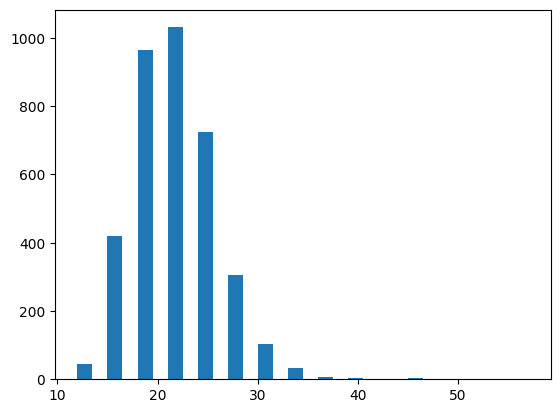

In [40]:
plt.hist(count_df.sum(axis=1), 30)

In [35]:
# PCA
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
scaler = StandardScaler()
normalized_data = scaler.fit_transform(count_df)
pca = PCA(n_components=3)
principal_components = pca.fit_transform(normalized_data)


In [36]:
scatter(principal_components, heclass)

In [43]:
phate_op_coarse = phate.PHATE(n_components=3, random_state=0)
count_coarse_phate = phate_op_coarse.fit_transform(count_coarse)

Calculating PHATE...
  Running PHATE on 3640 observations and 5 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.12 seconds.
    Calculating affinities...
    Calculated affinities in 0.07 seconds.
  Calculated graph and diffusion operator in 0.20 seconds.
  Calculating landmark operator...
    Calculating SVD...


/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning:

Detected zero distance between 9620 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.

/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:454: RuntimeWarning:

overflow encountered in power



    Calculated SVD in 0.20 seconds.
    Calculating KMeans...
    Calculated KMeans in 4.87 seconds.
  Calculated landmark operator in 5.60 seconds.
  Calculating optimal t...
    Automatically selected t = 33
  Calculated optimal t in 0.70 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.17 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 25.54 seconds.
Calculated PHATE in 32.22 seconds.


In [44]:
scatter(count_coarse_phate, heclass, s=2)

In [45]:
scaler_coarse = StandardScaler()
normalized_data_coarse = scaler_coarse.fit_transform(count_coarse)
pca_coarse = PCA(n_components=3)
principal_components_coarse = pca_coarse.fit_transform(normalized_data_coarse)


In [46]:
scatter(principal_components_coarse, heclass)